---
title: Monitors
bibliography:
  - ../references.bib
---

# Monitors

{term}`Monitors <Monitor>` are part of TVB's observation layer. They have the role of recording your data during the simulation and will determine the shape of the output synthtic data (after running `tvb.simulator.simulator.run()`), specifically their dimensionality and temporal resolution. 

The monitor is responsible for watching the simulation as it runs — deciding which quantities to record, at what temporal resolution, and in what form (raw state, region-space averages, or sensor-space projections). It also supplies the forward models needed to turn simulated source activity into experimentally comparable signals such as EEG, MEG, and BOLD fMRI. Nothing a monitor does feeds back into the dynamics (with the deliberate exception of Bold, which carries its own internal state), so the module is functionally a set of passive observers attached to a Simulator.

There are different types of monitors. You can use a a single monitor or combine several monitors to record simulatanously. 
- **Types of monitors**:
  -  [Raw and reduction monitors](#reduction-monitor)
  -  [Sensor-space monitors: EEG, sEEG, MEG](#sensor-space)
  -  [bold monitors](#BOLD-monitor)
  -  [Coupling monitors](#Coupling-monitor)
  -  [Diagnostic monitors](#Diagnostic-monitor)


Beyond the type description, this page covers three topics. Jump to whichever you need.
- **[How to set up a monitor for your simulation](#setup-guide)**.
- **[How to choose the period](#choose-period)**.
- **[Note on volume vs. surface simulation](#surface-note)**.
- **[API reference](#api-reference)**, with commentary and common pitfalls.

___
(reduction-monitor)=

### 1. **Reduction monitors**: 
monitors that differ in how aggressively they decimate the raw data through spatial and temportal downsampling. This is particularily useful to save memory and storage space. The below table describes how each monitor deals with the temporal and spatial dimension and the state variables:


| Monitor | Spatial dimension (brin areas) | Temporal dimensions (integration steps) | Model state variables | Notes|
|---|---|---|---|---|
| [`Raw()`](/tvb-simulator-monitors/#cls-tvb-simulator-monitors-raw) | all | all | all | Records every state variable at every integration step, |
| [`RawVoi()`](/tvb-simulator-monitors/#cls-tvb-simulator-monitors-rawvoi)| all | all | Variables of interest | Records variables of interest, which were defined in the [model](/bb-model/) or setting the monitor `variables_of_interest`|
| [`SubSample()`](/tvb-simulator-monitors/#cls-tvb-simulator-monitors-subsample)| all | downsamples to the given `period` | all | records at a coarser cadence than the integration step size|
| [`TemporalAverage()`](/tvb-simulator-monitors/#cls-tvb-simulator-monitors-temporalaverage)| all | averages consecutive raw samples within each `period` | | see notes on chosing the `period` below |
| [`SpatialAverage()`](/tvb-simulator-monitors/#cls-tvb-simulator-monitors-spatialaverage) | averages across selected regions | all | all | |
| [`GlobalAverage()`](/tvb-simulator-monitors/#cls-tvb-simulator-monitors-globalaverage) | average over all regions | all | all |  “convenience” monitor for quickly checking|

To learn more, have a look at the monitor in the general monitor [API reference](/tvb-simulator-monitors/).

#### <u>The difference between temporal downsampling and averaging</u>

While `SubSample()` records the instantaneous state at every sampling period step of the time series. Doing this, it could miss fast fluctuations between samples and may introduce bias.

 `TemporalAverage()` computes the mean state over all integration steps within each sampling period.It smooths and attenuates fast fluctuations, comparable to a moving-average low-pass filter. 
 
For example, with an integration step size `dt` of **0.1 ms** and a monitor `period` of **1 ms**:
- `SubSample()` records the state approximately once every 10 integration steps.
- `TemporalAverage()` averages the states from each 10-step interval and records one mean value per interval.

To learn how to set up your monitor got to the **[setup guide](#setup-guide)**.


___
(sensor-space)=
### 2. **Sensor-space projection monitors**: 
Sensor-space projection monitors allow you to project your simulated source-data on a sensor-based modality of your choice. Currently implemented are EEG, MEG, and iEEG (not ECoG). 

Those monitors act as forward models: they hold projection/lead-field information and electrode or sensor-set configuration. Using this, they linearly map simulated region or surface activity (source space) into the corresponding sensor space. 

These monitors keep the reference of which sources project to which sensors and validate projection shapes against the loaded connectivity.

Available sensor-space monitors are: [`EEG()`](tvb-simulator-monitors/#cls-tvb-simulator-monitors-eeg), [`MEG()`](tvb-simulator-monitors/#cls-tvb-simulator-monitors-meg) and [`iEEG()`](tvb-simulator-monitors/#cls-tvb-simulator-monitors-ieeg).

All three monitors need some crucial incredients to function: 
 
`projection` : The gain / lead-field matrix that maps source space activity onto sensors, with shape n_sensors × n_vertices. 
- If you have a precomputed  projection matrix/forward solution (e.g. from MNE or FieldTrip), you can use this here (Learn how too use your own anatomical data for projection in this [tutorial](PLACEHOLDER link to tutorial)). 
- If you do not have a projection matrix, you can either use a default projection from tvb.datatypes.
  ```python
  from tvb.datatypes.projections import ProjectionSurfaceEEG

  pr = ProjectionSurfaceEEG(load_default=True)
  ```
- If you do not want to use a projection matrix, the monitor provides a method to calculate a single sphere approximation of the head to get a projection matrix. Have a look in the [`API reference`](tvb-simulator-monitors/#cls-tvb-simulator-monitors-eeg).

`sensors`: A full TVB Sensors object describing the EEG electrode set,  containing locations, labels, types and montage. 
- You can import your own sensor information, as described in this [tutorial](PLACEHOLDER link to tutorial)
- You can also use a default projection from tvb.datatypes.
  ```python
  from tvb.datatypes.sensors import SensorsEEG

  sensors = SensorsEEG(load_default=True)
  ```

`region_mapping`: specifies how vertices of a surface correspond to given region in the connectivity.
- If you have a precomputed `region_mapping` from your own data, you can use this here (Learn how too use your own anatomical data for projection in this [tutorial](PLACEHOLDER link to tutorial)). 
- If you do not have a individual `region_mapping`, you can either use one from `tvb.datatypes`.
  ```python
  from tvb.datatypes.region_mapping import RegionMapping

  rm = RegionMapping(load_default=True)
  ```

`period`: see section on [how to choose the period](#choose-period)

To learn how to set up the monitor, go to the **[setup guide](#setup-guide)**.


___
(BOLD-monitor)=
### 3. **Blood Oxygenation Level Dependent (BOLD) monitors**: 

The `Bold()` monitor is is the most elaborate member of the module, as it is not a passive observer. Rather than simply reading state, it embeds a hemodynamic forward model, which is a Balloon–Windkessel model driven by the simulated neural activity through a haemodynamic response kernel. The monitor integrates that alongside the main simulation, producing an fMRI-observable time series with its own sampling characteristics.

Available monitors are:
- [`Bold()`](tvb-simulator-monitors/#cls-tvb-simulator-monitors-bold) The basic Bold monitor where can read out BOLD signal for each area in your simulation.
- [`BoldRegionROI()`](tvb-simulator-monitors/#cls-tvb-simulator-monitors-boldregionroi) (only used for surface simulation) used to generate regional signals which are the spatial average of all vertices in the region.

To learn how to set up your monitor got to the **[setup guide](#setup-guide)**.

To use this monitor, there are some important attributes to set:
`length`: duration of the hrf in seconds.
`period`: see section on [how to choose the period](#choose-period)
`hrf_kernel`: the haemodynamic response function (HRF) used to compute the BOLD (Blood Oxygenation Level Dependent) signal.
    In the current implementation TVB has HRF kernels: 
    -   a Gamma function,
    -   a difference of two damped oscillators
    -   a first order Volterra kernel
    -   a mixture of gamma functions
    
    
*** <u> Chosing your `hrf_kernel`</u> ***

In [1]:
from tvb.simulator.lab import monitors, equations
bold = monitors.Bold()
bold.dt = 2**-4
bold.compute_hrf()

/Users/lotte/Documents/Teaching_Supervision/DOCATHON/tvb-docs/.venv/lib/python3.14/site-packages/tvb/datatypes/surfaces.py:60: UserWarning: Geodesic distance module is unavailable; some functionality for surfaces will be unavailable.
  warnings.warn(msg)


The default kernel is the **Volterra kernel**. The shape of this function depends on the following parameters: 

1. $\tau_s$, rate constant of signal decay;
2. $\tau_f$, rate constant of feedback regulation;

* $V_0$ and $k_1$ are parameters used in the monitor to scale the amplitude of the response. See [@friston_nonlinear_2000]. 

Let's have a look at the function:

By default, the method **compute_hrf** gives the reflected version of the HRF. The product between this reflected HRF and the monitor's neural activity history (convolution) yields the BOLD signal. In python the indexing [::-1] will give the HRF kernel as often seen in scientific publications. 

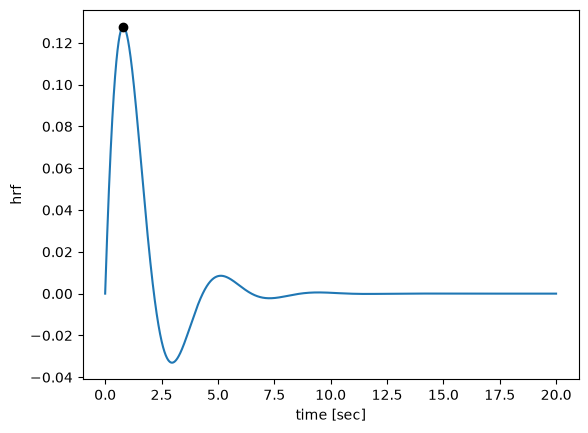

In [2]:
import matplotlib.pyplot as plt
# plot the kernel
plt.plot(bold._stock_time, bold.hemodynamic_response_function.T[::-1]); 
plt.ylabel('hrf');
plt.xlabel('time [sec]')

# plot the maximum
plt.plot(bold._stock_time[bold.hemodynamic_response_function.T[::-1].argmax()], bold.hemodynamic_response_function.T[::-1].max(), 'ko')

In [3]:
print ('Rising peak is around %1.2f seconds' % bold._stock_time[bold.hemodynamic_response_function.T[::-1].argmax()])

Rising peak is around 0.80 seconds


*** Exploring other HRF kernels ***
 
First, we will create new instances of the Bold monitor.

Second, the equation defining the hrf kernel has to be changed. To achieve this we will make use of the predefined functions as Equations datatypes 

- In [@boynton_linear_1996] they used a simple gamma function; in [@polonsky_neuronal_2000] a difference of damped oscillators was fitted to functional data from the visual cortex; the mixture of gammas is the function used in softwares like SPM. 

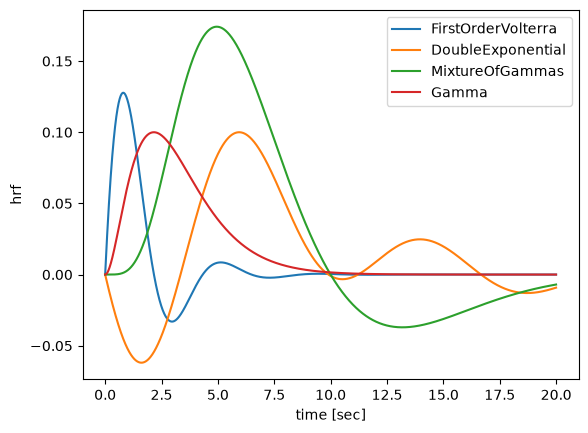

In [4]:
hrf_kernels = [equations.FirstOrderVolterra(),
               equations.DoubleExponential(),
               equations.MixtureOfGammas(),
               equations.Gamma()]

plt.figure()
for hrf in hrf_kernels: 
    bold_monitor = monitors.Bold(hrf_kernel=hrf)
    bold_monitor.dt = 2**-4
    bold_monitor.compute_hrf()
    plt.plot(bold_monitor._stock_time,
         bold_monitor.hemodynamic_response_function.T[::-1], 
         label=hrf.__class__.__name__);

plt.ylabel('hrf');
plt.xlabel('time [sec]')    
plt.legend()

___
(Coupling-monitor)=
### 4. **Coupling monitors**: 
Coupling monitor observe the input side of the simulation rather than the local dynamics output. It records the incoming [coupling](bb-coupling) input received by each region, letting users inspect the effective connectivity signal that the model sees during integration. As a counterpart to the state monitors, it is useful for understanding why a network behaved as it did rather than merely what it did. It can also be useful for debugging and for analysing inter-regional drive independently of local dynamics.

Available coupling monitors are:
- [`AfferentCoupling()`](tvb-simulator-monitors/#cls-tvb-simulator-monitors-afferentcoupling): monitor that records the `variables_of_interest` from node_coupling data over all brain regions

- [`AfferentCouplingTemporalAverage()`](tvb-simulator-monitors/#cls-tvb-simulator-monitors-afferentcouplingtemporalaverage): monitors the time-averaged value for the model’s coupling variable/s of interest over all brain regions. (have a look above to learn more on temporal averaging and how to chose the `period`)

To learn how to set up your monitor got to the **[setup guide](#setup-guide)**.

___
(Diagnostic-monitor)=
### 5. **Diagnostic monitors**: 
The purpose of diagnostic monitors is operational rather than scientific.ProgressLogger and IntProgressLogger report simulation progress (text and integer-valued respectively) rather than scientific data.

Available coupling monitors are:
- [`ProgressLogger()`](tvb-simulator-monitors/#cls-tvb-simulator-monitors-progresslogger):  reports the progress of a running simulation as text, via TVB's logging machinery.

- [`IntProgressLogger()`](tvb-simulator-monitors/#cls-tvb-simulator-monitors-intprogresslogger): exposes progress as an integer-valued signal, designed for programmatic consumers (progress bars, GUI widgets) rather than human eyes.

___
(choose-period)=
#### <u>Chosing the `period`</u>
The sampling period is a parameter which needs to be set to temporally downsample (`SubSample()`) or average (`TemporalAverage()`) your signal. Sampling period is in milliseconds and must be an integral multiple of the chosen integration-step size `dt` (see [Integration](/bb-integrators/)). For example, if you simulate data with an integration step size `dt` of 0.01 ms(corresponding to 100.000 Hz), you can chose a period of 1 to retain a signal with a sampling period of 1 Hz. The integration step size `dt` must always be smaller than the `period`. 

To make sure you are using an appropriate period for downsampling or temporal averaging, always have a look at the raw signal first and compare it to the temporally-reduced version. Make sure the temporally-reduced version preserves the dynamics you are interested in. 

Let's import the modules we need.

In [5]:
%matplotlib inline

In [6]:
%%capture

import os

import numpy as np
import matplotlib.pylab as plt

from tvb.simulator.lab import *

We will start where we left off in the first tutorial.

In [7]:
# spatial context - the connectivity
conn = connectivity.Connectivity.from_file( os.path.abspath('dataset/connectivity_76.zip'))
conn.configure()

# configure stimulus spatial pattern
weighting = np.zeros((conn.number_of_regions, ))
weighting[[0, 7, 13, 33, 42]] = np.array([2.0 ** -2, 2.0 ** -3, 2.0 ** -4, 2.0 ** -5, 2.0 ** -6])

# temporal profile
eqn_t = equations.Gaussian()
eqn_t.parameters["midpoint"] = 25000.0 # ms
eqn_t.parameters["sigma"] = 200.0 # ms

stimulus = patterns.StimuliRegion(temporal=eqn_t,
                                  connectivity=conn,
                                  weight=weighting)

FileNotFoundError: [Errno 2] No such file or directory: '/Users/lotte/Documents/Teaching_Supervision/DOCATHON/tvb-docs/content/user-guide/dataset/connectivity_76.zip'

In [ ]:
sim = simulator.Simulator(
    model=models.Generic2dOscillator(a=np.array([0.5])),
    connectivity=conn,
    coupling=coupling.Linear(a=np.array([0.0126])),
    integrator=integrators.HeunDeterministic(dt=0.5),
    monitors=(
        monitors.TemporalAverage(period=1.0),
        monitors.Bold(period=500),
        monitors.ProgressLogger(period=5e3),
    ),
    stimulus=stimulus,
    simulation_length=60e3, # 1 minute simulation
).configure()

(tavg_time, tavg_data), (bold_time, bold_data), _ = sim.run()

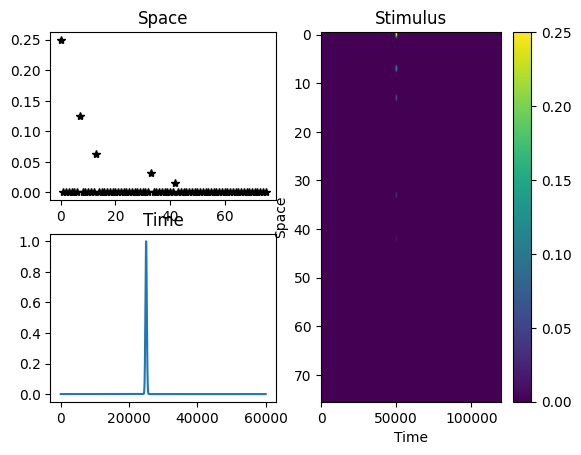

In [ ]:
plot_pattern(sim.stimulus)

If we zoom in and add the temporal average and BOLD time series, we can observe the instant response of the system to the stimulus, and the delayed BOLD peak.

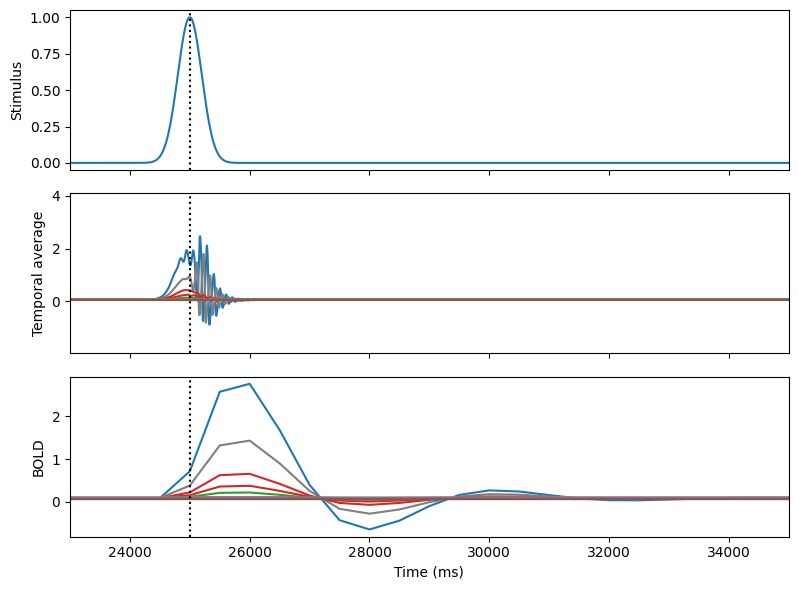

In [ ]:
fig, axs = plt.subplots(nrows=3, sharex=True, figsize=(8,6))

t0=23000 # ms
t1=35000 # ms

ax = axs[0]
ax.plot(sim.stimulus.time[0,], sim.stimulus.temporal_pattern[0])
ax.set(ylabel="Stimulus")

ax = axs[1]
ax.plot(tavg_time, tavg_data[:, 0, :, 0])
ax.set(ylabel="Temporal average")

ax = axs[2]
ax.plot(bold_time, bold_data[:, 0, :, 0])
ax.set(ylabel="BOLD", xlabel='Time (ms)', xlim=[t0,t1])


for ax in axs:
    ax.axvline(x=25000, c='k', ls=':')

fig.tight_layout()

Let's say we want to know what HRF other kernels are available in TVB. First we take a look at the BOLD monitor, and look for the `hrf_kernel` attribute:

In [ ]:
monitors.Bold?

Init signature: monitors.Bold(**kwargs)
Docstring:     
Traited class [tvb.simulator.monitors.Bold]
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^



    Base class for the Bold monitor.

    **Attributes**

        hrf_kernel: the haemodynamic response function (HRF) used to compute the BOLD (Blood Oxygenation Level Dependent) signal.

        length    : duration of the hrf in seconds.

        period    : the monitor's period

    **References**:

    .. [B_1997] Buxton, R. and Frank, L., *A Model for the Coupling between
        Cerebral Blood Flow and Oxygen Metabolism During Neural Stimulation*,
        17:64-72, 1997.

    .. [Fr_2000] Friston, K., Mechelli, A., Turner, R., and Price, C., *Nonlinear
        Responses in fMRI: The Balloon Model, Volterra Kernels, and Other
        Hemodynamics*, NeuroImage, 12, 466 - 477, 2000.

    .. [Bo_1996] Geoffrey M. Boynton, Stephen A. Engel, Gary H. Glover and David
        J. Heeger (1996). Linear Systems Analysis of Functional Magnetic Re

It says it's type is `tvb.datatypes.equations.HRFKernelEquation`, let's take a look what that is:

In [ ]:
equations.HRFKernelEquation?

Init signature: equations.HRFKernelEquation(**kwargs)
Docstring:     
Traited class [tvb.datatypes.equations.HRFKernelEquation]
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

Base class for hemodynamic response functions.

Attributes declared
"""""""""""""""""""

equation : tvb.datatypes.equations.Equation.equation = Attr(field_type=<class 'str'>, default=None, required=True)
    the equation as it should be interpreted by numexpr

parameters : tvb.datatypes.equations.Equation.parameters = Attr(field_type=<class 'dict'>, default=<function Equation.<lambda> at 0x78f1bf3f9ee0>, required=True)
    Should be a list of the parameters and their meaning, Traits
    should be able to take defaults and sensible ranges from any
    traited information that was provided.

gid : tvb.basic.neotraits._core.HasTraits.gid = Attr(field_type=<class 'uuid.UUID'>, default=None, required=True)
Init docstring:
The default init accepts kwargs for all declarative attrs
and sets them to the given v

Ok, so we see that the available variants (*subclasses*) are `Gamma`, `DoubleExponential`, `FirstOrderVolterra`, `MixtureOfGammas`. Let's take a look at the first one:

In [ ]:
equations.Gamma?

Init signature: equations.Gamma(**kwargs)
Docstring:     
Traited class [tvb.datatypes.equations.Gamma]
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


    A Gamma function for the bold monitor. It belongs to the family of Exponential functions.

    **Parameters**:


    * :math:`\tau`      : Exponential time constant of the gamma function [seconds].
    * :math:`n`          : The phase delay of the gamma function.
    * :math: `factorial` : (n-1)!. numexpr does not support factorial yet.
    * :math: `a`         : Amplitude factor after normalization.


    **Reference**:

    .. [B_1996] Geoffrey M. Boynton, Stephen A. Engel, Gary H. Glover and David
        J. Heeger (1996). Linear Systems Analysis of Functional Magnetic Resonance
        Imaging in Human V1. J Neurosci 16: 4207-4221

    .. note:: might be filtered from the equations used in Stimulus and Local Connectivity.

    

Attributes declared
"""""""""""""""""""

equation : tvb.datatypes.equations.Gamma.equation = Final(fi

Let's take it for a spin. 

In [ ]:
sim = simulator.Simulator(
    model=models.Generic2dOscillator(a=np.array([0.5])),
    connectivity=conn,
    coupling=coupling.Linear(a=np.array([0.0126])),
    integrator=integrators.HeunDeterministic(dt=0.5),
    monitors=(
        monitors.TemporalAverage(period=1.0),
        monitors.Bold(period=500, hrf_kernel=equations.Gamma()),
        monitors.ProgressLogger(period=5e3),
    ),
    stimulus=stimulus,
    simulation_length=60e3, # 1 minute simulation
).configure()

(tavg_time, tavg_data), (bold_time, bold_data), _ = sim.run()

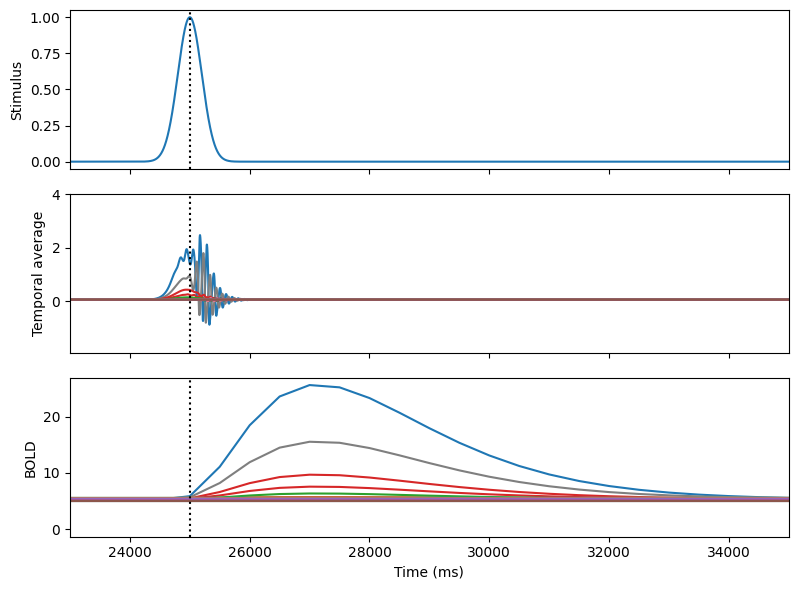

In [ ]:
fig, axs = plt.subplots(nrows=3, sharex=True, figsize=(8,6))

t0=23000 # ms
t1=35000 # ms

ax = axs[0]
ax.plot(sim.stimulus.time[0,], sim.stimulus.temporal_pattern[0])
ax.set(ylabel="Stimulus")

ax = axs[1]
ax.plot(tavg_time, tavg_data[:, 0, :, 0])
ax.set(ylabel="Temporal average")

ax = axs[2]
ax.plot(bold_time, bold_data[:, 0, :, 0])
ax.set(ylabel="BOLD", xlabel='Time (ms)', xlim=[t0,t1])


for ax in axs:
    ax.axvline(x=25000, c='k', ls=':')

fig.tight_layout()

Note: Such controlled experimentation is useful when trying to understand how are the particular components contributing to the final result.

Alternatively, we can also inspect the HRF kernels directly (see the [Exploring The Bold Monitor demo](https://nbviewer.thevirtualbrain.org/url/docs.thevirtualbrain.org/demos/exploring_the_bold_monitor.ipynb)).

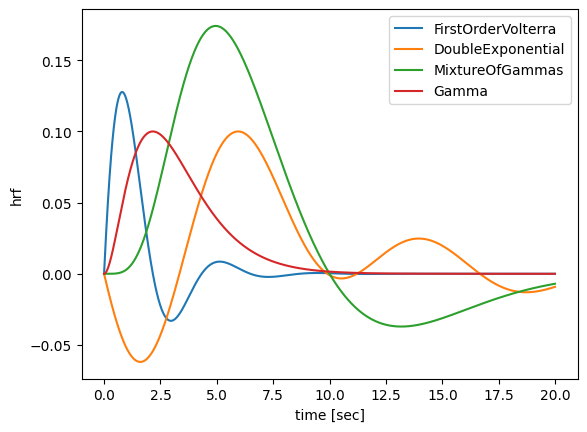

In [ ]:
hrf_kernels = [equations.FirstOrderVolterra(),
               equations.DoubleExponential(),
               equations.MixtureOfGammas(),
               equations.Gamma()]

plt.figure()
for hrf in hrf_kernels: 
    bold_monitor = monitors.Bold(hrf_kernel=hrf)
    bold_monitor.dt = 2**-4
    bold_monitor.compute_hrf()
    plt.plot(bold_monitor._stock_time,
         bold_monitor.hemodynamic_response_function.T[::-1], 
         label=hrf.__class__.__name__);

plt.ylabel('hrf');
plt.xlabel('time [sec]')    
plt.legend()